# 01 — Exploration des Signaux : Setup complet + Dataset WESAD réel (v2)

**Compression Adaptative de Signaux Physiologiques Multi-Capteurs par Sélection Dynamique
d'Algorithme via Métaheuristique**

1. Connexion Drive + structure de dossiers complète
2. Téléchargement du dataset WESAD réel (lien confirmé fonctionnel, 2.1 Go)
3. Chargement d'un sujet
4. Visualisation "punchline" sur 3 signaux contrastés (ECG/EDA/TEMP)
5. **Visualisation complète des 10 canaux multi-capteurs** (chest + wrist)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os

BASE = '/content/drive/MyDrive/Projet_Compression_WESAD'

# NOTE (correction) : Parquet_Format / HDF5_Format ne sont plus créés ici — le notebook 06
# les crée lui-même au moment d'écrire dedans (os.makedirs(..., exist_ok=True)). Les garder
# vides ici induisait le jury en erreur.
folders = [
    '1_Data_Raw',
    '3_Notebooks',
    '4_Results/Figures',
    '5_Docs',
]
for f in folders:
    os.makedirs(f'{BASE}/{f}', exist_ok=True)

print("Structure créée dans :", BASE)


Structure créée dans : /content/drive/MyDrive/Projet_Compression_WESAD


In [ ]:
!pip install -q pywavelets zstandard deap pyarrow
print("Librairies installées.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.1/93.1 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 21.4 MB/s eta 0:00:00
Librairies installées.


## Téléchargement du dataset réel + vérification renforcée

**Vérification en profondeur** : un fichier peut "exister" sur Drive (taille correcte,
zip valide) tout en étant corrompu si son écriture a été interrompue en cours de route
(ex: coupure réseau pendant l'extraction). On ne se contente donc plus de vérifier que
chaque `Sx.pkl` existe : on tente de le **charger réellement** (`pickle.load`) pour
confirmer qu'il n'est pas tronqué. En cas d'échec, tout le pipeline (téléchargement +
extraction) est **automatiquement retenté jusqu'à 3 fois**.

In [ ]:
import zipfile, pickle

WESAD_URL = "https://uni-siegen.sciebo.de/s/HGdUkoNlW1Ub0Gx/download"
zip_path = f'{BASE}/1_Data_Raw/WESAD.zip'
EXPECTED_ZIP_SIZE_GO = 2.1
extract_target = f'{BASE}/1_Data_Raw'
wesad_dir = f'{extract_target}/WESAD'
EXPECTED_SUBJECTS = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 15, 16, 17]  # S1, S12 exclus (cf. email du prof)


def zip_is_valid(path):
    if not os.path.exists(path):
        return False
    if os.path.getsize(path) / 1e9 < EXPECTED_ZIP_SIZE_GO * 0.95:
        return False
    try:
        with zipfile.ZipFile(path, 'r') as z:
            return z.testzip() is None
    except zipfile.BadZipFile:
        return False


def subject_is_valid(sid):
    """Vérification RÉELLE (pas juste os.path.exists) : tente de désérialiser le pickle.
    Détecte un fichier tronqué/corrompu que la seule présence du fichier ne révèle pas."""
    path = f'{wesad_dir}/S{sid}/S{sid}.pkl'
    if not os.path.exists(path):
        return False
    try:
        with open(path, 'rb') as f:
            data = pickle.load(f, encoding='latin1')
        return 'signal' in data and 'label' in data and len(data['label']) > 0
    except Exception:
        return False


def sujets_manquants():
    return [sid for sid in EXPECTED_SUBJECTS if not subject_is_valid(sid)]


def download_and_extract(missing):
    if not zip_is_valid(zip_path):
        if os.path.exists(zip_path):
            os.remove(zip_path)
        print(f"Téléchargement en cours (~{EXPECTED_ZIP_SIZE_GO} Go)...")
        os.system(f'wget -O "{zip_path}" "{WESAD_URL}"')
        if not zip_is_valid(zip_path):
            print("⚠️ Échec du téléchargement (zip invalide).")
            return
    print(f"{len(missing)} sujet(s) à (re)extraire : {missing}")
    with zipfile.ZipFile(zip_path, 'r') as z:
        members = [m for m in z.namelist() if any(f'S{sid}/' in m for sid in missing)] or None
        z.extractall(extract_target, members=members)


MAX_ATTEMPTS = 3
for attempt in range(1, MAX_ATTEMPTS + 1):
    missing = sujets_manquants()
    if not missing:
        print(f"✅ Intégrité RÉELLE vérifiée (pickle.load réussi) sur les {len(EXPECTED_SUBJECTS)} sujets.")
        break
    print(f"--- Tentative {attempt}/{MAX_ATTEMPTS} ---")
    download_and_extract(missing)
else:
    still_missing = sujets_manquants()
    if still_missing:
        print(f"⚠️ Après {MAX_ATTEMPTS} tentatives, encore manquants/corrompus : {still_missing}")
        print("   Vérifie ta connexion et l'espace Drive disponible, puis relance cette cellule.")

# Libère l'espace une fois l'intégrité RÉELLE confirmée
if not sujets_manquants() and os.path.exists(zip_path):
    freed_go = os.path.getsize(zip_path) / 1e9
    os.remove(zip_path)
    print(f"Zip supprimé, {freed_go:.2f} Go libérés sur le Drive.")


--- Tentative 1/3 ---
Téléchargement en cours (~2.1 Go)...
15 sujet(s) à (re)extraire : [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 15, 16, 17]
✅ Intégrité RÉELLE vérifiée (pickle.load réussi) sur les 15 sujets.
Zip supprimé, 2.25 Go libérés sur le Drive.


## Chargement d'un sujet

In [ ]:
import pickle
import numpy as np

wesad_dir = f'{BASE}/1_Data_Raw/WESAD'   # <-- adapte si besoin

def load_subject(subject_id, wesad_dir):
    path = f'{wesad_dir}/S{subject_id}/S{subject_id}.pkl'
    with open(path, 'rb') as f:
        return pickle.load(f, encoding='latin1')

print("Chargement du sujet S2...")
s2_data = load_subject(2, wesad_dir)
print("Chest :", list(s2_data['signal']['chest'].keys()))
print("Wrist :", list(s2_data['signal']['wrist'].keys()))


Chargement du sujet S2...
Chest : ['ACC', 'ECG', 'EMG', 'EDA', 'Temp', 'Resp']
Wrist : ['ACC', 'BVP', 'EDA', 'TEMP']


## Visualisation "punchline" : 3 signaux très contrastés

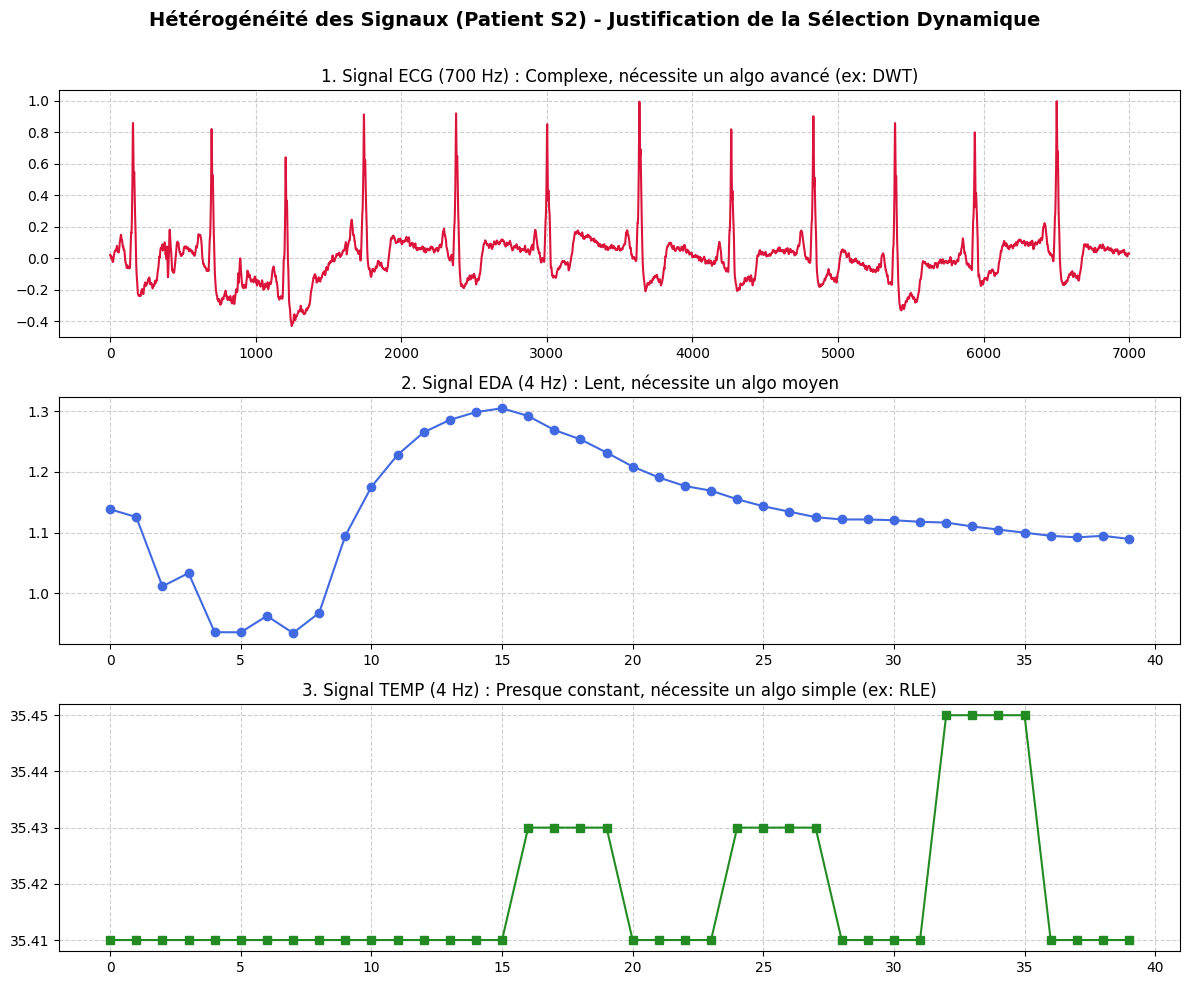

In [ ]:
ecg_signal = s2_data['signal']['chest']['ECG'].flatten()
eda_signal = s2_data['signal']['wrist']['EDA'].flatten()
temp_signal = s2_data['signal']['wrist']['TEMP'].flatten()

import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(12, 10))
fig.suptitle("Hétérogénéité des Signaux (Patient S2) - Justification de la Sélection Dynamique",
             fontsize=14, fontweight='bold')

axes[0].plot(ecg_signal[:7000], color='crimson')
axes[0].set_title("1. Signal ECG (700 Hz) : Complexe, nécessite un algo avancé (ex: DWT)")
axes[0].grid(True, linestyle='--', alpha=0.6)

axes[1].plot(eda_signal[:40], color='royalblue', marker='o')
axes[1].set_title("2. Signal EDA (4 Hz) : Lent, nécessite un algo moyen")
axes[1].grid(True, linestyle='--', alpha=0.6)

axes[2].plot(temp_signal[:40], color='forestgreen', marker='s')
axes[2].set_title("3. Signal TEMP (4 Hz) : Presque constant, nécessite un algo simple (ex: RLE)")
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.subplots_adjust(top=0.9)
plt.savefig(f'{BASE}/4_Results/Figures/heterogeneite_3signaux.png', dpi=150)
plt.show()


## Visualisation complète : les 10 canaux multi-capteurs

Poitrine (RespiBAN, 700 Hz) : ACC, ECG, EMG, EDA, Temp, Resp
Poignet (Empatica E4, fréquences variables) : ACC (32 Hz), BVP (64 Hz), EDA (4 Hz), TEMP (4 Hz)

Pour les capteurs ACC (accéléromètre 3 axes), on affiche la magnitude √(x²+y²+z²).

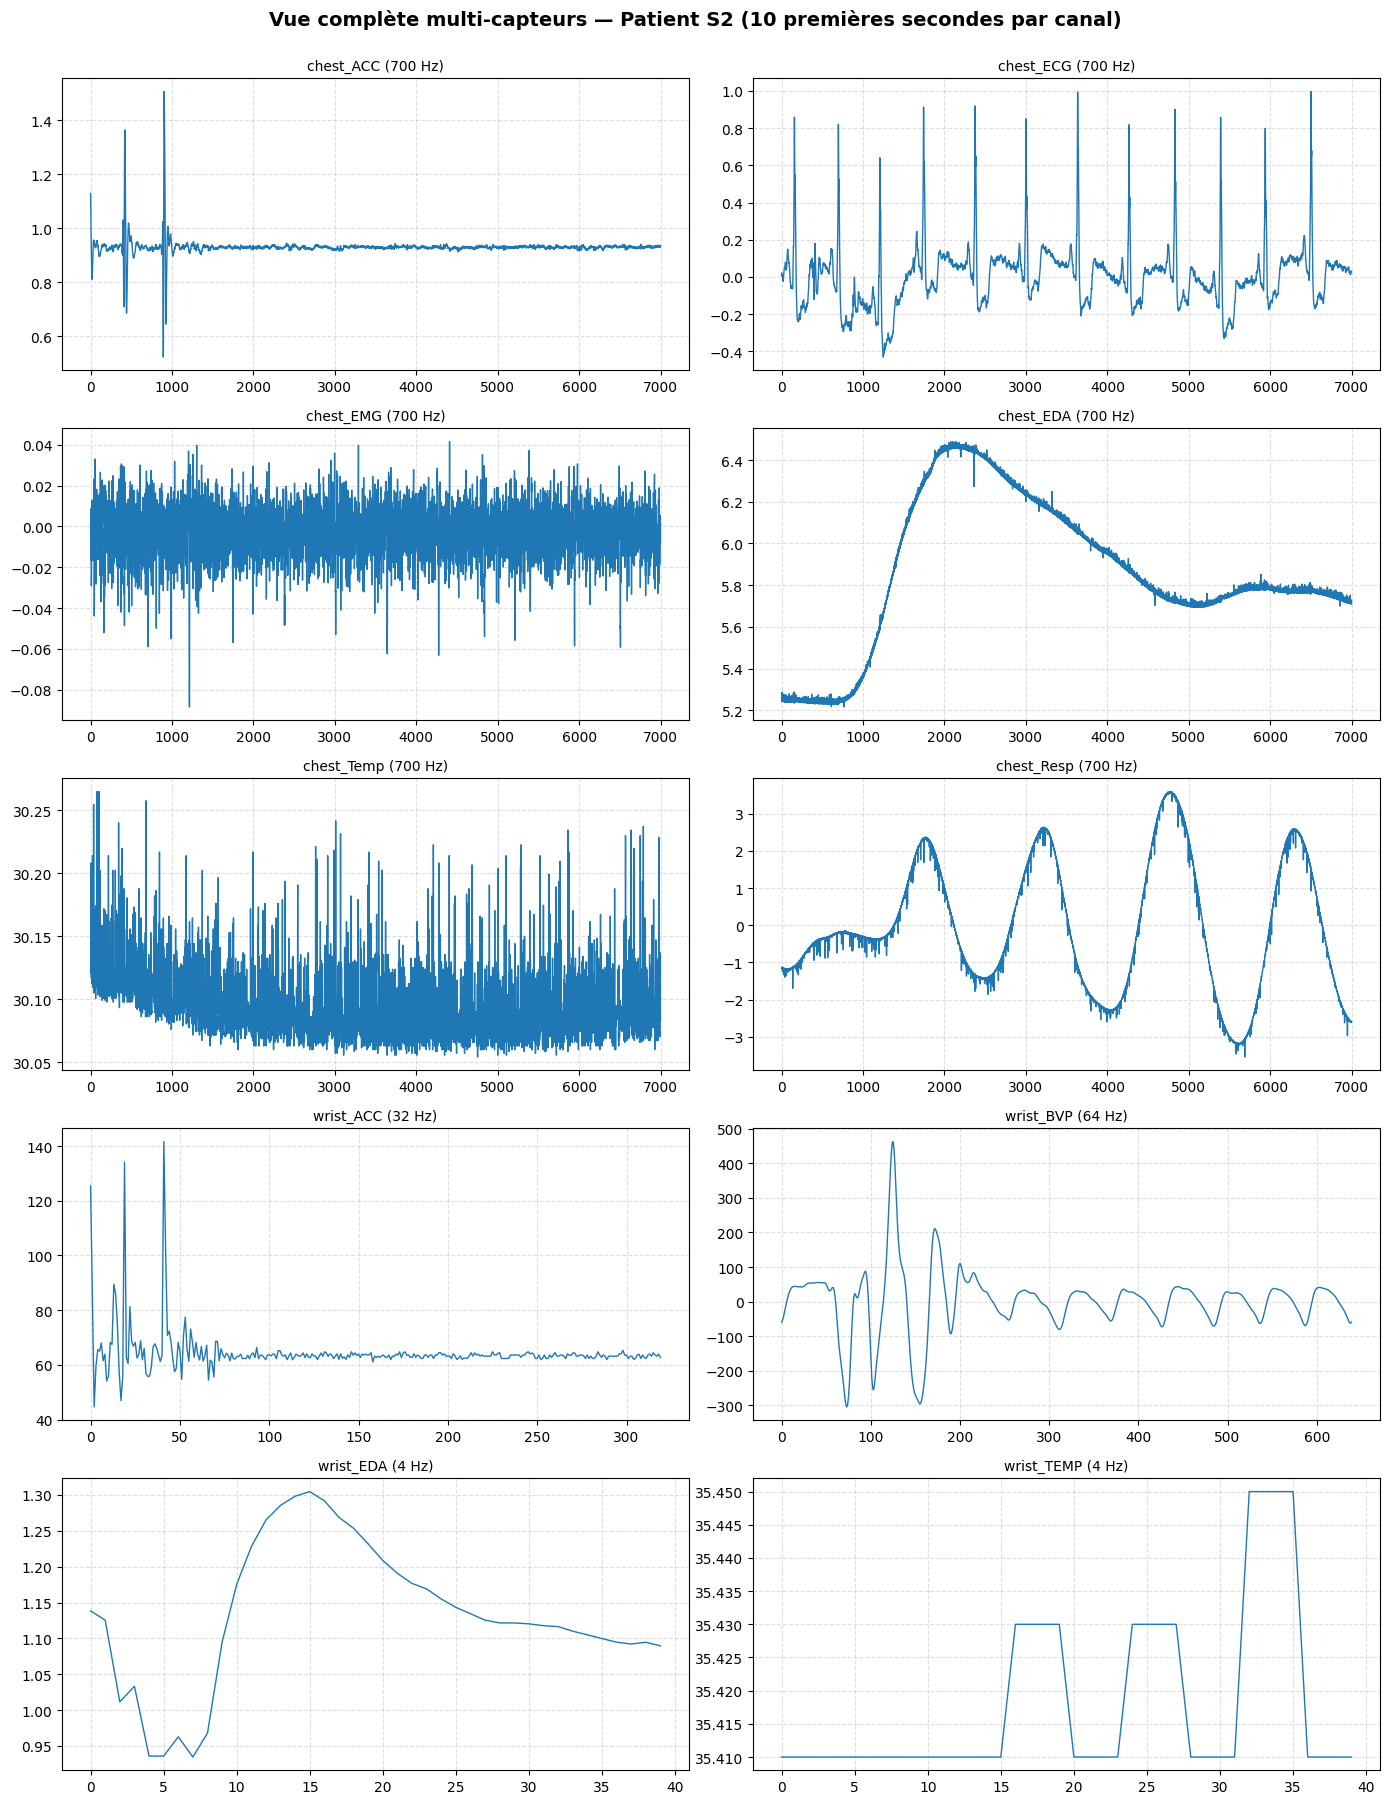

In [ ]:
CHANNELS_ALL = [
    {'name': 'chest_ACC',  'device': 'chest', 'key': 'ACC',  'fs': 700, 'multi_axis': True},
    {'name': 'chest_ECG',  'device': 'chest', 'key': 'ECG',  'fs': 700, 'multi_axis': False},
    {'name': 'chest_EMG',  'device': 'chest', 'key': 'EMG',  'fs': 700, 'multi_axis': False},
    {'name': 'chest_EDA',  'device': 'chest', 'key': 'EDA',  'fs': 700, 'multi_axis': False},
    {'name': 'chest_Temp', 'device': 'chest', 'key': 'Temp', 'fs': 700, 'multi_axis': False},
    {'name': 'chest_Resp', 'device': 'chest', 'key': 'Resp', 'fs': 700, 'multi_axis': False},
    {'name': 'wrist_ACC',  'device': 'wrist', 'key': 'ACC',  'fs': 32,  'multi_axis': True},
    {'name': 'wrist_BVP',  'device': 'wrist', 'key': 'BVP',  'fs': 64,  'multi_axis': False},
    {'name': 'wrist_EDA',  'device': 'wrist', 'key': 'EDA',  'fs': 4,   'multi_axis': False},
    {'name': 'wrist_TEMP', 'device': 'wrist', 'key': 'TEMP', 'fs': 4,   'multi_axis': False},
]

def get_signal_1d(data, ch):
    raw = data['signal'][ch['device']][ch['key']]
    if ch['multi_axis']:
        return np.linalg.norm(raw, axis=1)
    return raw.flatten()

fig, axes = plt.subplots(5, 2, figsize=(14, 18))
axes = axes.flatten()

for ax, ch in zip(axes, CHANNELS_ALL):
    sig = get_signal_1d(s2_data, ch)
    n = ch['fs'] * 10  # 10 secondes
    ax.plot(sig[:n], linewidth=1)
    ax.set_title(f"{ch['name']} ({ch['fs']} Hz)", fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.4)

fig.suptitle("Vue complète multi-capteurs — Patient S2 (10 premières secondes par canal)",
             fontsize=14, fontweight='bold', y=1.0)
plt.tight_layout()
plt.savefig(f'{BASE}/4_Results/Figures/tous_capteurs_S2.png', dpi=150, bbox_inches='tight')
plt.show()


## Volume total du dataset

In [ ]:
total_bytes = 0
for root, dirs, files in os.walk(wesad_dir):
    for f in files:
        if f.endswith('.pkl'):
            total_bytes += os.path.getsize(os.path.join(root, f))
print(f"Volume total de données brutes disponibles : {total_bytes / 1e9:.2f} Go")


Volume total de données brutes disponibles : 13.83 Go


## Prochaine étape\n\n`3_Notebooks/02_Algorithmes_Compression_v3.ipynb` — 6 algorithmes (RLE, LZ77, Huffman, Delta, DCT, DWT).

⚠️ **Important** : si des sujets apparaissaient comme "non disponibles" dans les notebooks
suivants malgré une extraction "réussie", la cause réelle était un **zip source tronqué**
(téléchargement interrompu jamais redétecté par l'ancien contrôle de taille). C'est corrigé
ci-dessus : le zip est maintenant vérifié par intégrité (taille + `testzip()`) avant d'être
considéré comme valide, et automatiquement re-téléchargé en entier s'il est corrompu. Si tu
avais déjà un zip ou des dossiers partiels d'une exécution précédente, relance simplement
les cellules de ce notebook — le nettoyage est automatique.